Порпобую, попытаюсь объяснить...

In [9]:
#Я тут, наимпортировал всякого, не обращайте внимания
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
import sys

project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "supporting_functions" / "datacleaner.py").is_file()
)
sys.path.insert(0, str(project_root))

Есть крайне интересное и непростое в своей структуре распределение, оно лежит в cal_pka_basic, хочется с аналитической точностью воспроизвести его значения. Для этого очень хочется построить функцию плотности вероятностей для этого распределения, но как это сделать - туманно, поэтому для начала давайте проведем некоторое дополнительное исследование.

Хороший способ оценки плотности вероятностей - KDE - kernel density estimation, по-русски ядерная оценка плотности, стоит поговорить о ней чуть подробнее, начнем с определения:

Положим, что у нас есть некая выборка $X = \{x_1, x_2, x_3,\cdots,x_n\}$, тогда для оценки плотности ее распределения имеет смысл следующая функция:

$$
\hat{f}_h(x)=\frac{1}{nh}
\sum_{i=1}^{n}
K\left(\frac{x-x_i}{h}\right)
$$

Где:
- $n$ — объём выборки;
- $x_i$ — отдельные наблюдения;
- $x$ — точка, в которой вычисляется плотность;
- $K(u)$ — ядерная функция;
- $h$ — ширина окна.

KDE представляет из себя взвешенную сумму некоторых(определяемых ядерной функцией) распределений построенных относительно каждого измерения, вес же, принимается равным для каждого распределения; $h$ - коэффициент сглаживания, как бы "снижающий дискретность" полученной функции, который напрямую влияет на количество видимых на графике пиков. Варьируя этот параметр, можно попробовать выделить стабильные пики и предположить какому закону подчиняется наше сложное распределение.



<Axes: title={'center': 'Kernel Density Estimate'}, xlabel='cal_pka_basic', ylabel='Density'>

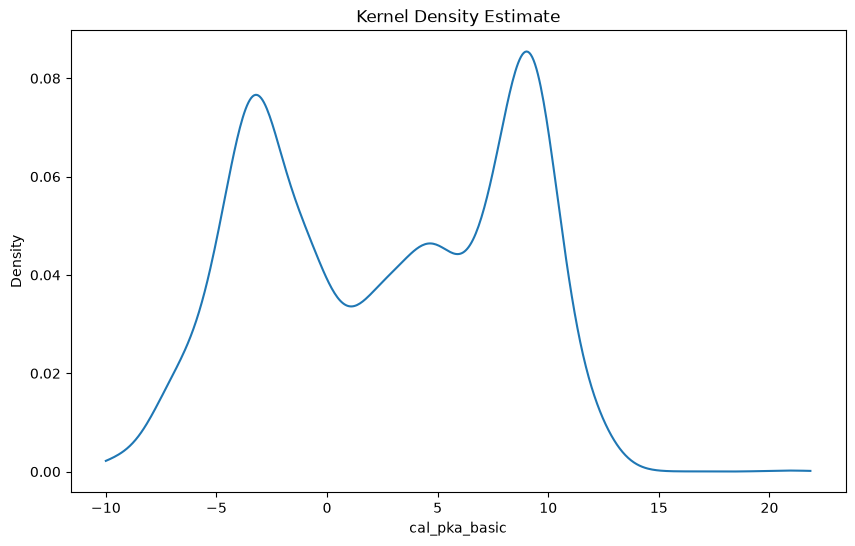

In [10]:
from supporting_functions.custom import plot_kde

def gaussian_kernel(u):
    return np.exp(-0.5 * u**2) / np.sqrt(2 * np.pi)

df = pd.read_csv(project_root / "cleaned_data.csv")
data = df["cal_pka_basic"].dropna().to_numpy(dtype=float)

plot_kde(data, h=1, kernel=gaussian_kernel)


При $h = 1$ видим примерно то, что было представлено в разборе, я сделал кастомную функцию, чтобы можно было посмотреть на поведение пиков при разных $h$ и ядрах распределения, если понадобится.
Давайте посмотрим на диапазон от 0.1 до 1.2; Уже заранее замечу, что на большинстве вырисовывается +- 3 стабильных пика, давайте это проверим честно:

h = 0.1, peak x-values: [-2.98  8.89  9.47]
h = 0.2, peak x-values: [-2.98  4.94  9.4 ]
h = 0.3, peak x-values: [-3.04  4.94  9.28]
h = 0.4, peak x-values: [-3.11 -1.19  9.21]
h = 0.5, peak x-values: [-3.17 -1.19  9.21]
h = 0.6, peak x-values: [-3.17  4.74  9.15]
h = 0.7, peak x-values: [-3.23  4.74  9.15]
h = 0.8, peak x-values: [-3.23  4.68  9.08]
h = 0.9, peak x-values: [-3.23  4.68  9.08]
h = 1.0, peak x-values: [-3.23  4.68  9.02]
h = 1.1, peak x-values: [-3.17  4.68  8.96]
h = 1.2, peak x-values: [-3.17  8.96]


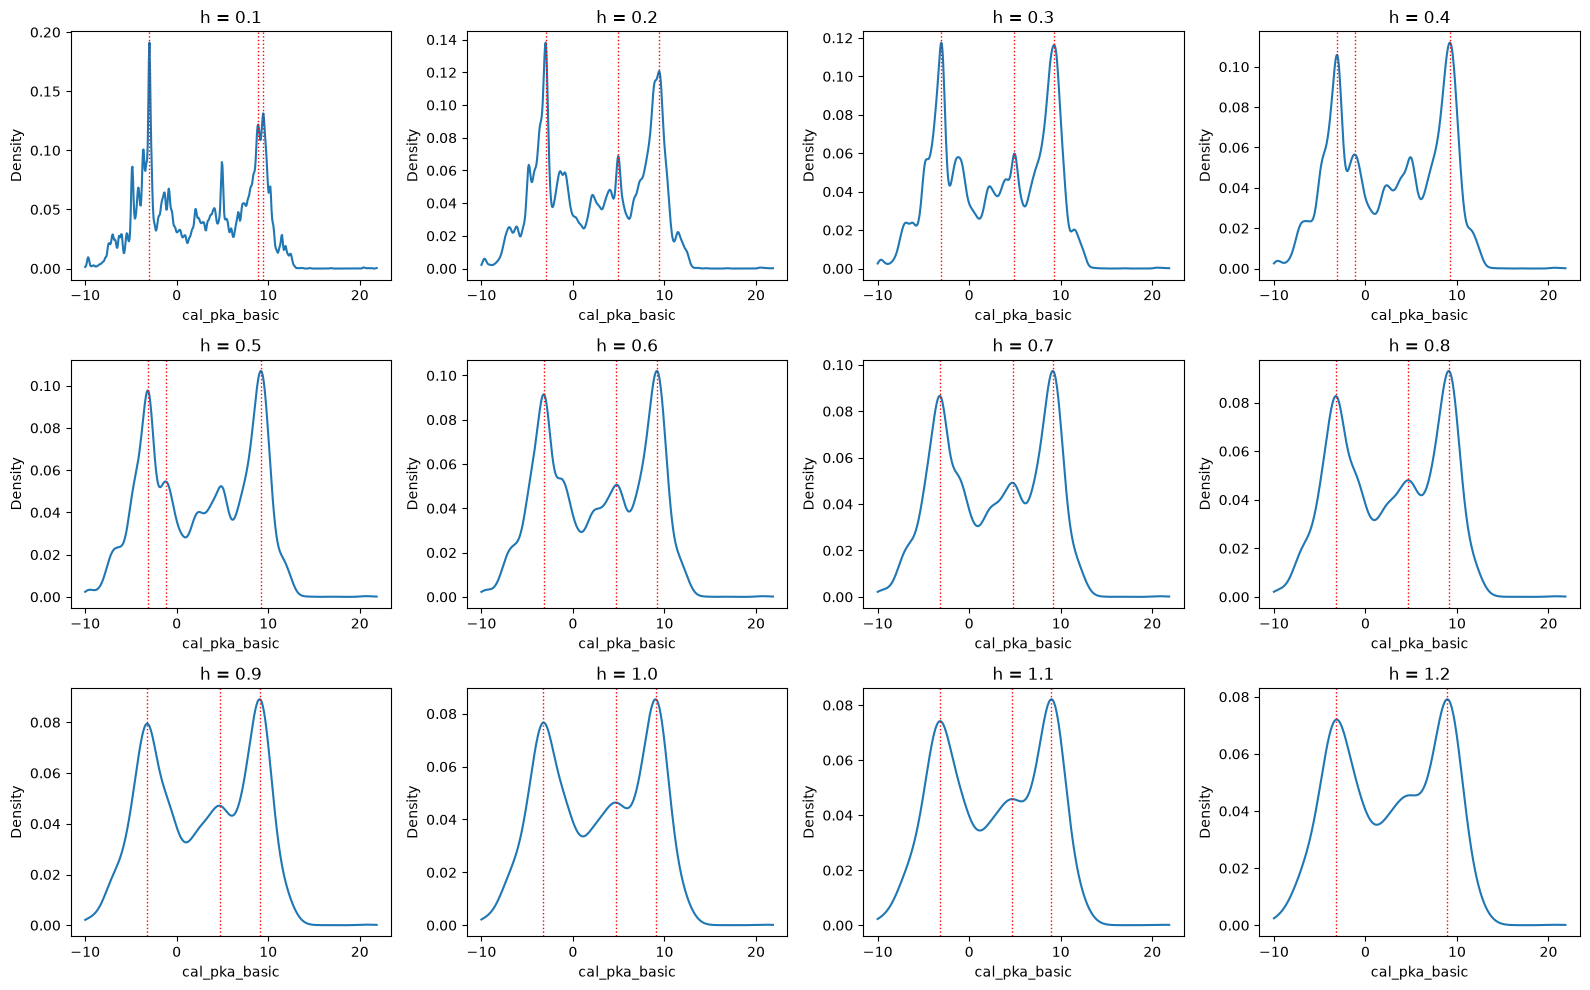

In [11]:
from supporting_functions.custom import kde, find_prominent_peaks

relative_prominence = 0.01

h_values = np.linspace(0.1, 1.2, 12)
x_grid = np.linspace(data.min(), data.max(), 500)
fig, axes = plt.subplots(3, 4, figsize=(16, 10))

for ax, h in zip(axes.flat, h_values):
    density = kde(data, x_grid, h=h, kernel=gaussian_kernel)
    ax.plot(x_grid, density)

    peak_indices = find_prominent_peaks(
        density, relative_prominence=relative_prominence
    )
    top_peaks = peak_indices[np.argsort(density[peak_indices])[-3:]]
    peak_values = np.sort(x_grid[top_peaks])

    print(f"h = {h:.1f}, peak x-values: {peak_values.round(2)}")
    for peak_x in peak_values:
        ax.axvline(peak_x, color="red", linestyle=":", linewidth=1)

    ax.set_title(f"h = {h:.1f}")
    ax.set_xlabel("cal_pka_basic")
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

Так, на 0.4-0.5 пики уехали, а на 0.1 вообще что-то странное на 1.2 третий пик пропал вовсе, очевидно, что все очень не просто, с другой стороны, кто сказал, что будет легко?

Как извлечь из этой фукции дополнительную информацию? Есть идея построить зависимость пиков(локальных максимумов) функции от ширины окна, чтобы получить своего рода мировые линии пиков при разном сглаживании KDE функции. Таким образом, "живучие" значения укажут нам на ключевые пики всего нашего распределения. 

Сразу отмечу, что проделав этот фокус в лоб, могут появиться очень странные значения, для этого распределения в окрестности 21 есть маленький бугорок, который не видно почти ни на одном значении ширны окна, но при этом он страшно стабильный и видимо вызван каким-то совпадающим измерением в этой области(несколько измерений буквально имели одно и то же число, что позволило им вырасти в пик). Чтобы это победить был введен фильтр отстояния от прочих значений на графике и хватило значения в 0.01, чтобы от него избавиться. Ниже приведу график до этой правки:
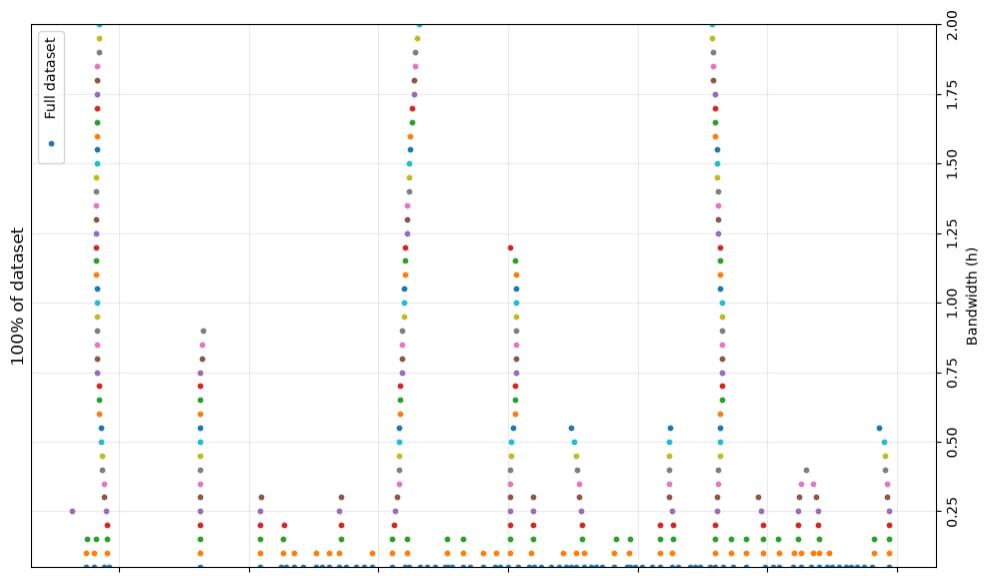

Не теряя общности, и в целях статистической корректности, следует рассматривать совокупное распределение на случайных выборках разного размера. Предлагаю выбирать по 25% и 50%; для каждого из этих экспериментов я проведу процедуру по 3 раза, после чего будет построен совокупный график для каждого из них:

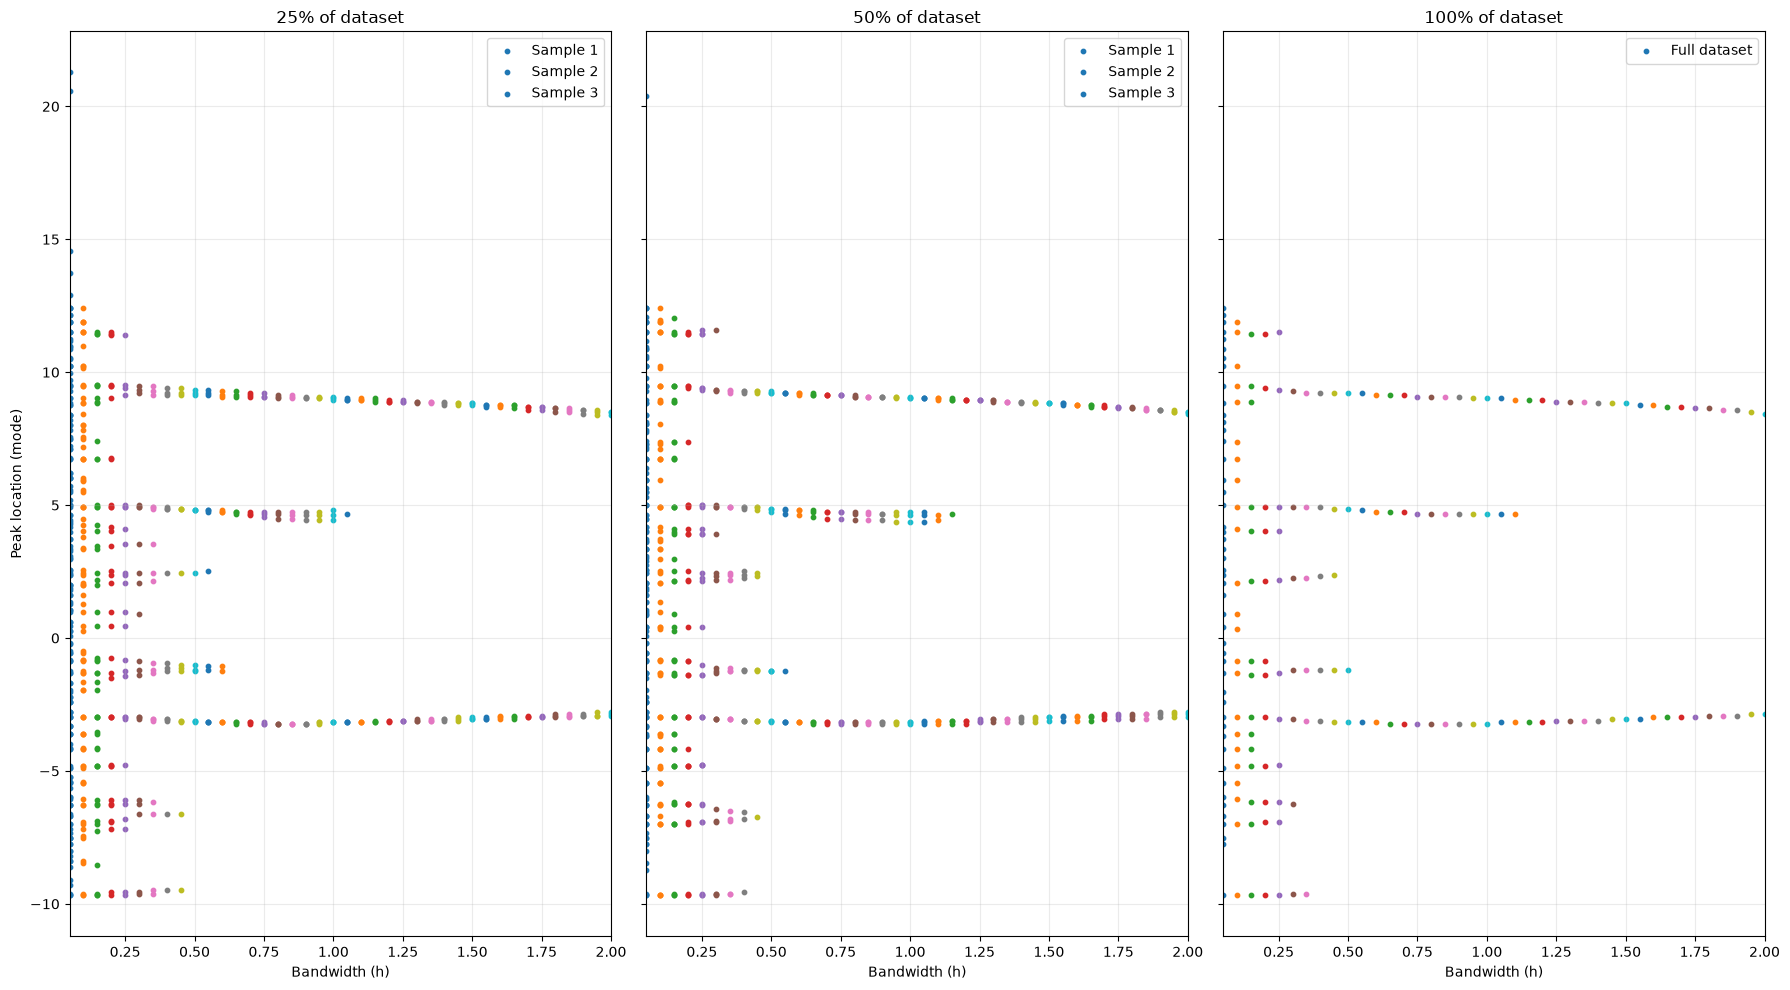

In [12]:
from supporting_functions.custom import kde, gaussian_kernel, find_prominent_peaks

relative_prominence = 0.01
values = np.asarray(data, dtype=float)
values = values[np.isfinite(values)]
if values.size == 0:
    raise ValueError("data contains no finite values")

h_values = np.round(np.arange(0.05, 2.001, 0.05), 2)
x_grid = np.linspace(values.min(), values.max(), 500)
rng = np.random.default_rng(42)

experiments = [
    (0.25, 3),
    (0.50, 3),
    (1.00, 1),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 10), sharey=True)

for ax, (fraction, repetitions) in zip(axes, experiments):
    sample_size = max(1, int(np.ceil(values.size * fraction)))

    for trial in range(repetitions):
        sample = (
            values
            if fraction == 1.0
            else rng.choice(values, size=sample_size, replace=False)
        )
        label = "Full dataset" if fraction == 1.0 else f"Sample {trial + 1}"

        for h in h_values:
            density = kde(sample, x_grid, h=h, kernel=gaussian_kernel)
            peak_indices = find_prominent_peaks(
                density, relative_prominence=relative_prominence
            )

            ax.scatter(
                np.full(peak_indices.size, h),
                x_grid[peak_indices],
                s=10,
                label=label if h == h_values[0] else None,
            )

    ax.set_title(f"{fraction:.0%} of dataset")
    ax.set_xlabel("Bandwidth (h)")
    ax.set_xlim(h_values[0], h_values[-1])
    ax.grid(alpha=0.25)
    ax.legend()

axes[0].set_ylabel("Peak location (mode)")
fig.tight_layout()
plt.show()

Теперь чётко видно наши 3 искомых пика, и пусть не формально, но доказано, что 3 пиковая модель имеет право на жизнь! Что это значит? Что мы начинаем предполагать и допускать!

Предположим, что эмпирическое распределение можно описать смесью трёх нормальных распределений:
$$
f(x)=\sum_{i=1}^{3}w_i\mathcal N(x\mid\mu_i,\sigma_i^2)
$$

У нас шесть неизвестных параметров формы и ещё два независимых веса (третий определяется условием суммы). Собственно, приплыли, не успев начать, но выход есть! Для матожидания и дисперсии формулы известны, вот только нужно как-то разделить выборку, давайте для начала проведем границы по минимуму KDE функции, чтобы окупить потраченное на нее время.

Почему это сработает, пусть и не точно, достаточно взглянуть на картинку (*сгенерированно ИИ)
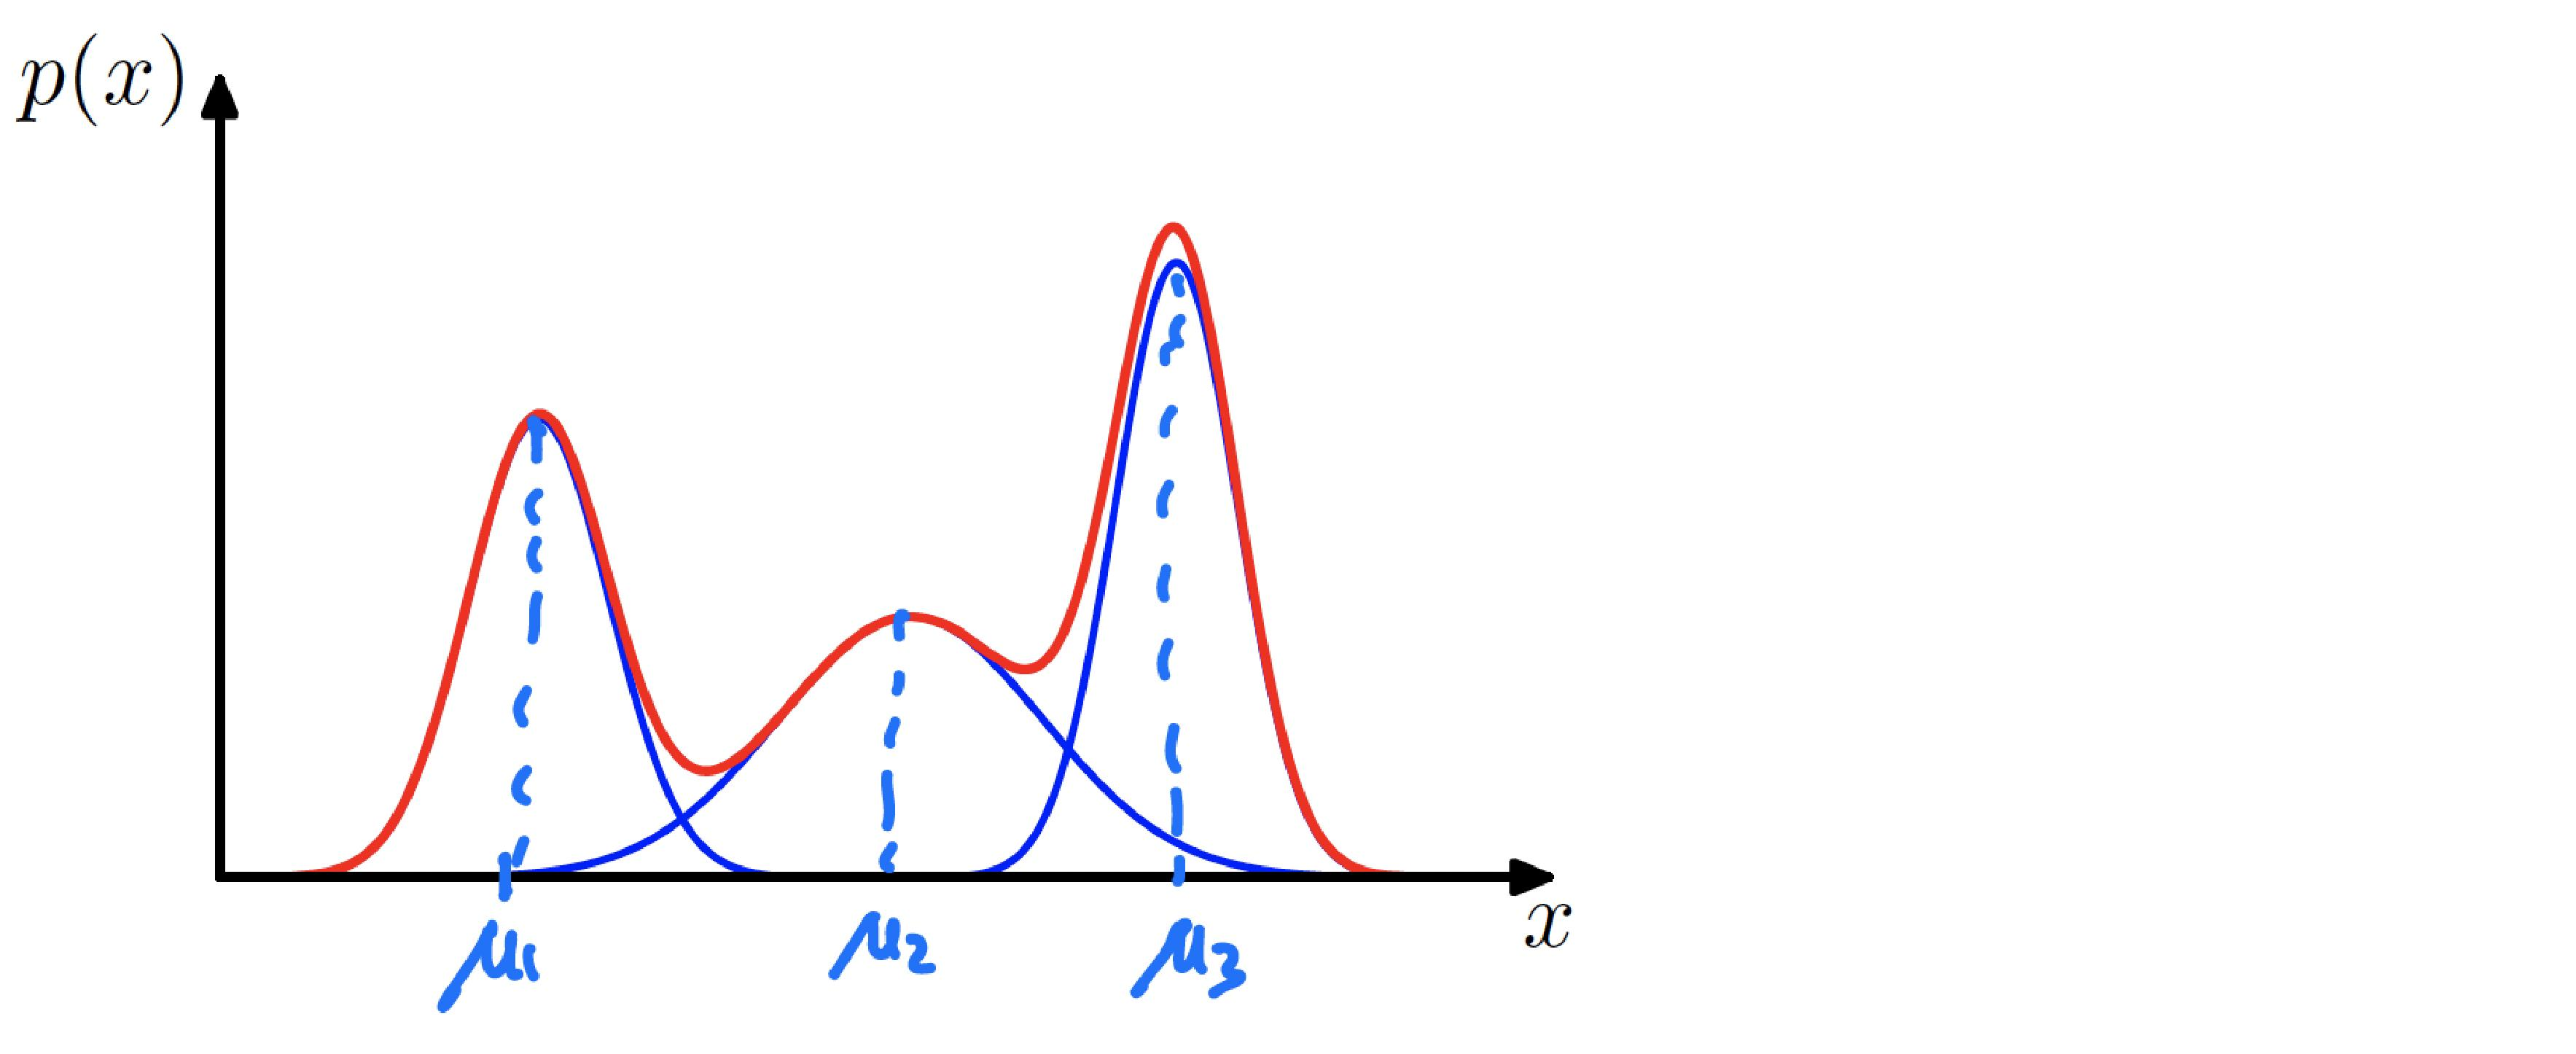

Дело в том, что в минимумах KDE функции пересекутся хвосты субпопуляций нашего распределения, это грубо оценивя $Q80-Q99$ - а они, в свою очередь, вносят не такой сущесвенный вклад в матожидание и дисперсию, значит какую-то оценку так дать можно.

Остается только вопрос, как подобрать $h$ для KDE - ведь от него зависит не только количество, но и глубина пиков, что может сказаться на значениях искомых величин. Давайте исследуем этот вопрос на разных значениях $h$. 

Если обратиться к графику "живучести" пиков, видно, что при $h \in [0.6, 1]$ значения максимумов устойчивы, ожижается, что прочие важные параметры проявят свою устойчивость в этом диапазоне, давайте это проверим:


In [13]:
from supporting_functions.custom import summarize_kde_groups

summary = summarize_kde_groups(data)
summary

,h,b_1(h),b_2(h),number_1,expected_value_1,variance_1,number_2,expected_value_2,variance_2,number_3,expected_value_3,variance_3
0,0.60,0.939289,6.120170,4139,-3.184167,4.593614,2066,3.710136,1.953196,3462,8.982998,2.168455
1,0.65,0.932883,6.121822,4139,-3.184167,4.593614,2066,3.710136,1.953196,3462,8.982998,2.168455
2,0.70,0.927077,6.123473,4132,-3.191136,4.572667,2073,3.700748,1.972621,3462,8.982998,2.168455
3,0.75,0.958258,6.125125,4139,-3.184167,4.593614,2066,3.710136,1.953196,3462,8.982998,2.168455
4,0.80,0.953954,6.090090,4139,-3.184167,4.593614,2060,3.703150,1.942079,3468,8.978025,2.178979
5,0.85,0.987237,6.054454,4152,-3.171165,4.633064,2036,3.707790,1.886742,3479,8.968850,2.198633
6,0.90,1.021722,6.018218,4161,-3.162133,4.660681,2014,3.704876,1.839829,3492,8.957912,2.222472
7,0.95,1.057407,5.981381,4169,-3.154069,4.685563,1994,3.701750,1.798036,3504,8.947785,2.244711
8,1.00,1.094294,5.906056,4179,-3.143959,4.716973,1953,3.679647,1.720080,3535,8.921434,2.303536


Давайте оценим полученные данные:

- Первая граница меняется примерно от 6.12 до 5.91.
- Вторая — от 3.71 до 3.68.
- Численность первой группы меняется на 40 наблюдений, второй — на 120, третьей — на 73; на 10000 наблюдений - это погрешность
- Средние и дисперсии меняются довольно слабо.

То есть основная чувствительность приходится на центральную группу, что вполне ожидаемо: при перемещении обеих границ меняется её размер с двух сторон.

Поэтому можно смело использовать серидину нашего устойчивого диапазона $h = 0.8$, как основного для построения модели, для сравнения можно построить и для $h = 0.6$ и $h = 1.0$

<Axes: title={'center': 'Original data and three-component normal mixtures'}, xlabel='cal_pka_basic', ylabel='Density'>

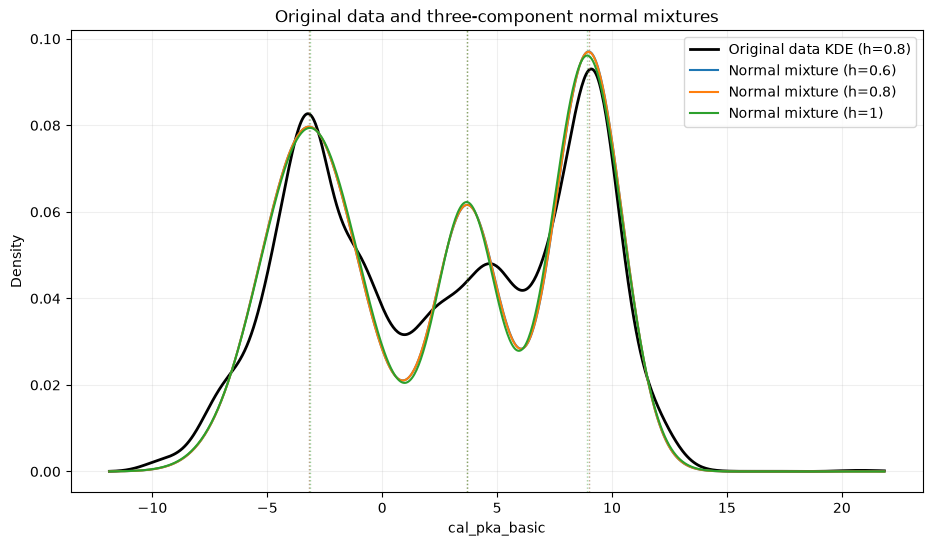

In [14]:
from supporting_functions.custom import plot_normal_mixture_comparison

plot_normal_mixture_comparison(data, summary)

Какие выводы можно сделать из полученного графкиа:
1. $h = 0.8$ - оптимально, отклонения незначительные, в дальнейшем не имеет смысла менять этот параметр
2. По крайним распределениям пики и хвосты сошлись вполне точно, чего нельзя сказать о последнем
3. Модель немного смещает третий пик относительно исходной KDE, а также не вполне воспроизводит его форму.
4. Впадины между пиками у модели получаются более выраженными, чем у исходного распределения.

Проблем много и причина в сущности одна - строгое разделение групп по минимуму KDE функции, за которым тянется ошибка. Наложение неравномерное и нужно как-то оценить куда должен сместиться центральный пик. Напришивается применение вероятностного подхода. И такой можно реализовать, формула Байеса поможет нам его сформулировать:

Если мы предварительно знаем параметры трёх компонент, то:
$$
p_{ik}=
\frac{w_k f_k(x_i)}
{\sum_{j=1}^{3}w_j f_j(x_i)}
$$

Где:
- $w_k$ — вес компоненты;
- $f_k(x_i)$— плотность соответствующего нормального распределения в точке $x_i$;
- $p_{ik}$ — вероятность того, что наблюдение $x_i$ относится к компоненте $k$.

Тогда взвешенные формулы параметров распределения приобретут следующий вид:

$$
\mu_k=
\frac{\sum_i p_{ik}x_i}{\sum_i p_{ik}}
$$

$$
\sigma_k^2=
\frac{\sum_i p_{ik}(x_i-\mu_k)^2}
{\sum_i p_{ik}}
$$

$$
w_k=\frac{1}{n}\sum_i p_{ik}
$$

Теперь напрашивается переход к задаче оптимизации функции с скрытым параметром, который можно ввести как $Z_i$, принимающий значения 1, 2 или 3 и соответственно характеризующий принадлежность к группе 1, 2 или 3.

Тогда модель имеет вид:
$$
P(Z_i=k)=w_k
$$

$$
X_i\mid Z_i=k\sim\mathcal N(\mu_k,\sigma_k^2).
$$

Здесь:
- $w_k$ — вероятность выбора компоненты;
- $\mu_k$ — её математическое ожидание;
- $\sigma_k$ — стандартное отклонение.

Тогда рассчет вероятности принадлежности наблюдения к той или иной группе будет выражен через формулу Байеса следующим образом:

$$
r_{ik}^{(t+1)}
=
\frac{
w_k^{(t)}f_k(x_i\mid\mu_k^{(t)},\sigma_k^{(t)})
}{
\displaystyle\sum_{j=1}^{3}
w_j^{(t)}f_j(x_i\mid\mu_j^{(t)},\sigma_j^{(t)})
}
$$

Не случайно для вероятности указан индекс $t+1$ - ведь это преобразование мы будем итерировать несколько раз пока не добьемся удовлетварительной сходимости.

Цикл замкнулся: получаем парметры -> пересчитываем вероятности -> из вероятностей строим новые параметры. Осталось определить начальные условия и для как нельзя кстати подойдет распределение полученное из разделения по минимумам KDE функции. Осталось только все аккуратно посчитать и построить:

In [16]:
from IPython.display import display
from supporting_functions.custom import kde, probabilities_opt

initial_cons = summary.loc[np.isclose(summary["h"], 0.8)].iloc[0]
opt_steps = 5
optimization_history = probabilities_opt(data, initial_cons, opt_steps)

parameter_columns = [
    f"{parameter}_{component}"
    for component in range(1, 4)
    for parameter in ("weight", "expected_value", "variance")
]
optimization_table = (
    optimization_history.groupby("iteration")[parameter_columns]
    .first()
    .reset_index()
)
display(optimization_table)

all_means = optimization_table[
    [f"expected_value_{component}" for component in range(1, 4)]
].to_numpy()
max_sigma = np.sqrt(
    optimization_table[
        [f"variance_{component}" for component in range(1, 4)]
    ].to_numpy().max()
)
x_grid = np.linspace(
    min(data.min(), (all_means - 4 * max_sigma).min()),
    max(data.max(), (all_means + 4 * max_sigma).max()),
    500,
)
original_density = kde(data, x_grid, h=0.8)
fig, optimization_axes = plt.subplots(
    opt_steps, 1, figsize=(11, 3 * opt_steps), sharex=True, sharey=True
)
component_colors = ("tab:blue", "tab:orange", "tab:green")
for step, ax in zip(range(1, opt_steps + 1), optimization_axes):
    state = optimization_table.loc[optimization_table["iteration"] == step].iloc[0]
    mixture_density = np.zeros_like(x_grid)
    for component, color in enumerate(component_colors, start=1):
        mean = state[f"expected_value_{component}"]
        variance = state[f"variance_{component}"]
        weight = state[f"weight_{component}"]
        sigma = np.sqrt(variance)
        component_density = (
            np.exp(-0.5 * ((x_grid - mean) / sigma) ** 2)
            / (sigma * np.sqrt(2 * np.pi))
        )
        mixture_density += weight * component_density
        ax.axvline(mean, color=color, linestyle=":", linewidth=1, alpha=0.5)

    ax.plot(x_grid, original_density, color="black", label="Original data KDE")
    ax.plot(
        x_grid,
        mixture_density,
        color="tab:red",
        label="Three-normal mixture",
    )
    ax.set_title(f"EM approximation step {step}")
    ax.set_ylabel("Density")
    ax.grid(alpha=0.2)
    ax.legend()

optimization_axes[-1].set_xlabel("cal_pka_basic")
fig.tight_layout()
plt.show()

ImportError: cannot import name 'probabilities_opt' from 'supporting_functions.custom' (c:\Users\User\Desktop\StatsLab1\supporting_functions\custom.py)